**Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación - CICESE
Dr. Irvin Hussein López Nava

## ICD - 16: Máquinas de soporte vectorial

Sesión 16 del curso. Diapositivas: [icd-16-maquinas-soporte-vectorial.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-16-maquinas-soporte-vectorial.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-16-maquinas-soporte-vectorial.ipynb)

Las sesiones 13 a 15 abrieron tres cajas negras de la sesión 12: el árbol de decisión, Naive Bayes y el vecino más cercano. Hoy abrimos la última de la unidad 4: **la máquina de soporte vectorial** (SVM). De todas las fronteras que separan las clases, busca la que deja el mayor margen, y la escribe con unos cuantos ejemplos, los vectores de soporte.

El notebook tiene cinco partes. En la primera resolvemos un SVM a mano con cuatro puntos, con las cuentas de las diapositivas 12 a 16: el margen de dos rectas, la recta de margen máximo, el dual y un descenso por subgradiente. En la segunda vemos el margen suave con la holgura de cada punto, la pérdida bisagra y los kernels, también con números. En la tercera volvemos a los 14 días de la sesión 15: calculamos a mano la decisión del día 15 y elegimos $C$ y $\gamma$ sin mirar la prueba. En la cuarta llevamos el SVM al vino con el protocolo del notebook 13 y cerramos la unidad con una tabla. En la quinta vemos cómo maneja varias clases, qué hacen los pesos por clase y cuánto cuesta entrenarlo.

---

### Preparación

Las bibliotecas de siempre, más `scipy` para resolver el dual a mano en la sección 1.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scipy       ", scipy.__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.5.3
pandas       3.0.5
scipy        1.18.1
scikit-learn 1.9.1


Paleta y estilo de las sesiones anteriores. En las figuras de dos clases, los positivos van en azul y los negativos en naranja, como en las diapositivas.

In [2]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})

SEMILLA = 42        # fija las particiones para que los resultados se repitan

---

### Los datos

- `weather.numeric.csv` y `weather.prueba.csv` son los 14 días de entrenamiento y los 14 de prueba del caso de estudio de la sesión 15; `weather.nominal.csv` es la versión nominal de las sesiones 13 y 14.
- `vinos-3clases.csv` es el vino de 3 clases de la sesión 12.

En las cuatro lecturas, la primera línea funciona tal cual desde la carpeta del repositorio clonado. En Colab, comenta la primera y descomenta la segunda.

In [3]:
nominal = pd.read_csv("datos/weather.nominal.csv")
# nominal = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.nominal.csv")

entrena = pd.read_csv("datos/weather.numeric.csv")
# entrena = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.numeric.csv")

prueba = pd.read_csv("datos/weather.prueba.csv")
# prueba = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.prueba.csv")

vinos = pd.read_csv("datos/vinos-3clases.csv")
# vinos = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/vinos-3clases.csv")

print(f"Días: {len(entrena)} de entrenamiento y {len(prueba)} de prueba. Vinos: {len(vinos)}.")

Días: 14 de entrenamiento y 14 de prueba. Vinos: 1599.


---

## 1. Un SVM a mano

### Cuatro puntos

El ejemplo de las diapositivas 12 a 14: dos positivos, (2, 2) y (3, 3), y dos negativos, (0, 0) y (−1, 0). Muchas rectas los separan (diapositiva 7). La distancia con signo de cada punto a una recta $w \cdot x + b = 0$ es $d_j = y_j(w\cdot x_j + b)/\lVert w\rVert$ (diapositiva 9), y el **margen** de la recta es la menor:

$$\gamma = \min_j \frac{y_j\,(w\cdot x_j + b)}{\lVert w \rVert}$$

Si algún punto queda del lado equivocado, el mínimo es negativo: la recta no separa. Las rectas A y B de la diapositiva 12, y una tercera:

In [4]:
X4 = np.array([[2, 2], [3, 3], [0, 0], [-1, 0]], dtype=float)
y4 = np.array([1, 1, -1, -1])


puntos = ["(2, 2)", "(3, 3)", "(0, 0)", "(−1, 0)"]


def distancias(w, b, X, y):
    # distancia con signo de cada punto a la recta w·x + b = 0
    w = np.asarray(w, dtype=float)
    return y * (X @ w + b) / np.linalg.norm(w)


def margen(w, b, X, y):
    # la menor de esas distancias
    return distancias(w, b, X, y).min()


rectas = {"A: x1 + x2 = 1": ([1, 1], -1), "B: x1 = 1": ([1, 0], -1), "x1 + x2 = 2": ([1, 1], -2)}
tabla = pd.DataFrame({nombre: distancias(w_, b_, X4, y4) for nombre, (w_, b_) in rectas.items()}, index=puntos)
tabla.loc["margen (el mínimo)"] = tabla.min()
print("y =", y4)
tabla.round(2)

y = [ 1  1 -1 -1]


,A: x1 + x2 = 1,B: x1 = 1,x1 + x2 = 2
"(2, 2)",2.12,1.0,1.41
"(3, 3)",3.54,2.0,2.83
"(0, 0)",0.71,1.0,1.41
"(−1, 0)",1.41,2.0,2.12
margen (el mínimo),0.71,1.0,1.41


**Lectura.** En A, $w = (1, 1)$, $b = −1$ y $\lVert w\rVert = \sqrt{2}$. Para (0, 0), $d = (−1)(0 + 0 − 1)/\sqrt{2} = 0.71$: es su punto más cercano y fija el margen. En B, $w = (1, 0)$ y $\lVert w\rVert = 1$: (2, 2) y (0, 0) empatan a 1.00. La recta $x_1 + x_2 = 2$, que pasa a la mitad de (0, 0) y (2, 2), llega a 1.41 ($\sqrt{2}$). ¿Hay alguna mejor?

### La recta de margen máximo, paso a paso

Las cuentas de la diapositiva 13. Si los más cercanos de cada clase, (2, 2) y (0, 0), quedan sobre el margen, $w\cdot(2, 2) + b = 1$ y $w\cdot(0, 0) + b = −1$. La segunda da $b = −1$; con eso, la primera queda $2w_1 + 2w_2 − 1 = 1$, o sea $w_1 + w_2 = 1$. Entre todos esos $w$ buscamos el de menor $\frac{1}{2}\lVert w\rVert^2$:

In [5]:
b_mano = -1.0                                   # de w·(0, 0) + b = −1
w1 = np.array([0, 0.25, 0.5, 0.75, 1])          # sobre la recta w1 + w2 = 1
print(pd.DataFrame({"w1": w1, "w2": 1 - w1, "½||w||²": 0.5 * (w1 ** 2 + (1 - w1) ** 2)}).to_string(index=False))
w_mano = np.array([0.5, 0.5])                   # la derivada de ½[w1² + (1 − w1)²] es 2·w1 − 1: se anula en w1 = ½
print("\nw =", w_mano, "  b =", b_mano)
print("y_j (w·x_j + b) =", y4 * (X4 @ w_mano + b_mano), "  (todas ≥ 1)")
print(f"margen 1/||w|| = {1 / np.linalg.norm(w_mano):.3f}   banda 2/||w|| = {2 / np.linalg.norm(w_mano):.3f}"
      f"   ||(2, 2) − (0, 0)|| = {np.linalg.norm(X4[0] - X4[2]):.3f}   ½||w||² = {0.5 * w_mano @ w_mano}")

  w1   w2  ½||w||²
0.00 1.00   0.5000
0.25 0.75   0.3125
0.50 0.50   0.2500
0.75 0.25   0.3125
1.00 0.00   0.5000

w = [0.5 0.5]   b = -1.0
y_j (w·x_j + b) = [1.  2.  1.  1.5]   (todas ≥ 1)
margen 1/||w|| = 1.414   banda 2/||w|| = 2.828   ||(2, 2) − (0, 0)|| = 2.828   ½||w||² = 0.25


**Lectura.** $\frac{1}{2}\lVert w\rVert^2$ baja hasta $w_1 = ½$ y vuelve a subir. Con $w = (½, ½)$ y $b = −1$, las cuatro restricciones $y_j(w\cdot x_j + b) \ge 1$ valen 1, 2, 1 y 1.5: se cumplen, con igualdad solo en los dos vectores de soporte. La recta es $½x_1 + ½x_2 − 1 = 0$, es decir, $x_1 + x_2 = 2$. El margen, $1/\lVert w\rVert = \sqrt{2} = 1.41$, y la banda, $2/\lVert w\rVert = 2.83$, que es justo la distancia entre (0, 0) y (2, 2).

Escoger los vectores de soporte a ojo fue una suposición. Un optimizador no la necesita.

### El primal con scikit-learn

`SVC(kernel="linear")` resuelve el SVM de margen suave (diapositiva 23). Con un $C$ enorme, ninguna violación sale barata y queda el margen duro de la diapositiva 11. `coef_` e `intercept_` son $w$ y $b$; `support_vectors_`, los vectores de soporte; `dual_coef_`, los $\alpha_j y_j$ (diapositiva 30).

In [6]:
from sklearn.svm import SVC

duro = SVC(kernel="linear", C=1e8).fit(X4, y4)
w, b = duro.coef_[0], duro.intercept_[0]
print("w =", w.round(3), "  b =", round(b, 3), "  margen 1/||w|| =", round(1 / np.linalg.norm(w), 3))
print("vectores de soporte:", duro.support_vectors_.tolist())
print("alfa_j · y_j:", duro.dual_coef_[0].round(3))
print("y_j (w·x_j + b):", (y4 * (X4 @ w + b)).round(2))

w = [0.5 0.5]   b = -1.0   margen 1/||w|| = 1.414
vectores de soporte: [[0.0, 0.0], [2.0, 2.0]]
alfa_j · y_j: [-0.25  0.25]
y_j (w·x_j + b): [1.  2.  1.  1.5]


**Lectura.** Es la recta que encontramos a mano, escrita con $a = 1$ (diapositiva 10): $w = (½, ½)$ y $b = −1$. Los vectores de soporte, (0, 0) y (2, 2), quedan sobre $w \cdot x + b = \pm 1$, con $y_j(w\cdot x_j + b) = 1$; los otros dos, más lejos (2 y 1.5).

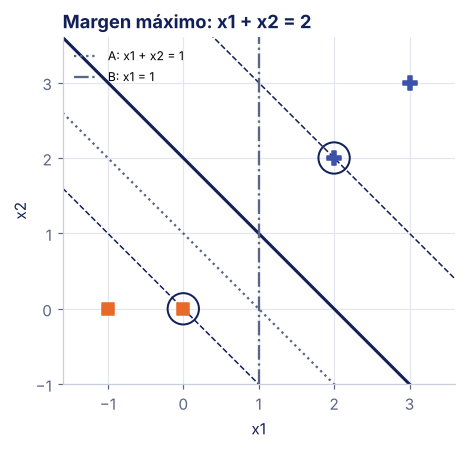

In [7]:
def dibuja_svm(ax, X, y, w, b, vs=None, limites=(-1.6, 3.6, -1.0, 3.6)):
    # la frontera w·x + b = 0 (línea continua), el margen w·x + b = ±1 (líneas punteadas) y los vectores de soporte (círculos)
    xs = np.linspace(limites[0], limites[1], 50)
    for c in [0, 1, -1]:
        ax.plot(xs, (c - b - w[0] * xs) / w[1], color=AZUL_OSCURO, linewidth=2 if c == 0 else 1, linestyle="-" if c == 0 else "--")
    ax.scatter(*X[y == 1].T, marker="P", s=90, color=AZUL_MEDIO, zorder=3)
    ax.scatter(*X[y == -1].T, marker="s", s=60, color=NARANJA, zorder=3)
    if vs is not None:
        ax.scatter(*vs.T, s=420, facecolors="none", edgecolors=AZUL_OSCURO, linewidths=1.3, zorder=4)
    ax.set_xlim(limites[0], limites[1])
    ax.set_ylim(limites[2], limites[3])
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(4.6, 4.2))
dibuja_svm(ax, X4, y4, w, b, vs=duro.support_vectors_)
xs = np.linspace(-1.6, 3.6, 50)
ax.plot(xs, 1 - xs, color=GRIS, linestyle=":", label="A: x1 + x2 = 1")
ax.axvline(1, color=GRIS, linestyle="-.", label="B: x1 = 1")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Margen máximo: x1 + x2 = 2")
ax.legend(loc="upper left", fontsize=8)
plt.show()

### Leer la solución

Con $f(x) = w\cdot x + b$, un punto nuevo se lee en tres partes (diapositiva 14): el signo da la clase, $|f| < 1$ dice que cae dentro de la banda, y $f/\lVert w\rVert$ es su distancia a la frontera. Para (1, 2):

In [8]:
nuevo = np.array([1.0, 2.0])
f_nuevo = w @ nuevo + b
print(f"f(1, 2) = ½·1 + ½·2 − 1 = {f_nuevo:.2f}")
print(f"signo: {'+' if f_nuevo > 0 else '−'}   |f| = {abs(f_nuevo):.2f} {'< 1: dentro de la banda' if abs(f_nuevo) < 1 else '≥ 1: fuera de la banda'}"
      f"   distancia f/||w|| = {f_nuevo / np.linalg.norm(w):.2f}")
print("decision_function:", duro.decision_function([nuevo]).round(2))

f(1, 2) = ½·1 + ½·2 − 1 = 0.50
signo: +   |f| = 0.50 < 1: dentro de la banda   distancia f/||w|| = 0.71
decision_function: [0.5]


**Lectura.** $f = 0.5$: es positivo, cae dentro de la banda y queda a 0.71 de la frontera. `decision_function` devuelve justo $w\cdot x + b$.

### El dual, a mano

La diapositiva 15 deduce el dual con el Lagrangiano: igualar a 0 sus derivadas da $w = \sum_j \alpha_j y_j x_j$ y $\sum_j \alpha_j y_j = 0$, y al sustituir queda

$$\max_{\alpha}\ W(\alpha) = \sum_j \alpha_j - \frac{1}{2}\sum_j\sum_k \alpha_j \alpha_k\, y_j y_k\, x_j\cdot x_k \qquad \text{con } \alpha_j \ge 0 \ \text{ y } \ \sum_j \alpha_j y_j = 0$$

Los datos solo entran por los productos punto $x_j\cdot x_k$, la matriz de Gram. Con las etiquetas, $Q_{jk} = y_j y_k\, x_j\cdot x_k$ (diapositiva 16):

In [9]:
G = X4 @ X4.T                                   # G[j, k] = x_j·x_k
Q = np.outer(y4, y4) * G                        # Q[j, k] = y_j y_k x_j·x_k
display(pd.DataFrame(G.astype(int), index=puntos, columns=puntos).rename_axis("x_j·x_k"))
pd.DataFrame(Q.astype(int), index=puntos, columns=puntos).rename_axis("Q")

,"(2, 2)","(3, 3)","(0, 0)","(−1, 0)"
x_j·x_k,,,,
"(2, 2)",8,12,0,-2
"(3, 3)",12,18,0,-3
"(0, 0)",0,0,0,0
"(−1, 0)",-2,-3,0,1


,"(2, 2)","(3, 3)","(0, 0)","(−1, 0)"
Q,,,,
"(2, 2)",8,12,0,2
"(3, 3)",12,18,0,3
"(0, 0)",0,0,0,0
"(−1, 0)",2,3,0,1


**Lectura.** La fila de (0, 0) es de ceros: el origen no aporta a ningún producto punto. Si los vectores de soporte son (2, 2) y (0, 0), como en la diapositiva 13, los otros dos α valen 0 y la restricción $\alpha_1 + \alpha_2 = \alpha_3 + \alpha_4$ deja $\alpha_1 = \alpha_3 = a$. El dual queda en una sola variable: $W(a) = 2a − \frac{1}{2}a^2(Q_{11} + 2Q_{13} + Q_{33}) = 2a − \frac{1}{2}(8 + 0 + 0)a^2 = 2a − 4a^2$, cuya derivada, $2 − 8a$, se anula en $a = ¼$.

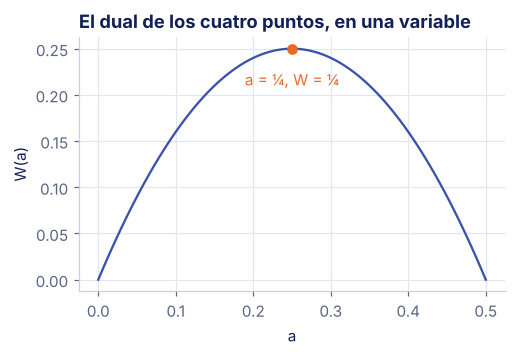

alfa = [0.25 0.   0.25 0.  ]   w = Σ alfa_j y_j x_j = [0.5 0.5]   W(alfa) = 0.25


In [10]:
a = np.linspace(0, 0.5, 101)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(a, 2 * a - 4 * a ** 2, color=AZUL_MEDIO)
ax.scatter([0.25], [0.25], color=NARANJA, zorder=3)
ax.annotate("a = ¼, W = ¼", (0.25, 0.25), textcoords="offset points", xytext=(0, -24), ha="center", color=NARANJA)
ax.set_xlabel("a")
ax.set_ylabel("W(a)")
ax.set_title("El dual de los cuatro puntos, en una variable")
plt.show()
alfa_mano = np.array([0.25, 0, 0.25, 0])
w_dual = (alfa_mano * y4) @ X4
print("alfa =", alfa_mano, "  w = Σ alfa_j y_j x_j =", w_dual, "  W(alfa) =", alfa_mano.sum() - 0.5 * alfa_mano @ Q @ alfa_mano)

**Lectura.** $w = ¼(2, 2) − ¼(0, 0) = (½, ½)$, el mismo del primal, y $W(¼) = ¼ = \frac{1}{2}\lVert w\rVert^2$: el dual llega al mismo valor que el primal.

`scipy.optimize.minimize` resuelve el mismo dual sin suponer cuáles son los vectores de soporte. Minimiza, así que le damos el dual con el signo cambiado.

In [11]:
from scipy.optimize import minimize


def menos_dual(alfa):
    return 0.5 * alfa @ Q @ alfa - alfa.sum()


sol = minimize(menos_dual, x0=np.zeros(4), method="SLSQP", bounds=[(0, None)] * 4,
               constraints=[{"type": "eq", "fun": lambda alfa: alfa @ y4}])
alfa = sol.x
print("alfa:", alfa.round(3))
print("w = Σ alfa_j y_j x_j =", ((alfa * y4) @ X4).round(3))
print("valor del dual:", round(-sol.fun, 3), "   ½||w||² del primal:", round(0.5 * w @ w, 3))

alfa: [0.25 0.   0.25 0.  ]
w = Σ alfa_j y_j x_j = [0.5 0.5]
valor del dual: 0.25    ½||w||² del primal: 0.25


**Lectura.** El optimizador encuentra los mismos $\alpha$: ¼ para (2, 2) y (0, 0), y 0 para los otros dos. Solo los vectores de soporte tienen $\alpha$ distinto de cero.

Con los $\alpha$ se recupera todo lo demás. $b$ sale de cualquier vector de soporte, $b = y_s − w\cdot x_s$, y la holgura complementaria, $\alpha_j[y_j f(x_j) − 1] = 0$, debe cumplirse en los cuatro puntos. Para clasificar no hace falta $w$: bastan los productos punto con los vectores de soporte (diapositiva 16).

In [12]:
for j in np.flatnonzero(alfa_mano > 0):
    print(f"b desde {puntos[j]}: y_s − w·x_s = {y4[j]} − {w_dual @ X4[j]:.0f} = {y4[j] - w_dual @ X4[j]:.0f}")
print("alfa_j [y_j f(x_j) − 1] =", alfa_mano * (y4 * (X4 @ w_dual - 1) - 1) + 0.0)
f_dual = sum(alfa_mano[j] * y4[j] * (X4[j] @ nuevo) for j in range(4)) - 1
print(f"(1, 2) con el dual: Σ alfa_j y_j (x_j·x) + b = ¼·6 − ¼·0 − 1 = {f_dual}")

b desde (2, 2): y_s − w·x_s = 1 − 2 = -1
b desde (0, 0): y_s − w·x_s = -1 − 0 = -1
alfa_j [y_j f(x_j) − 1] = [0. 0. 0. 0.]
(1, 2) con el dual: Σ alfa_j y_j (x_j·x) + b = ¼·6 − ¼·0 − 1 = 0.5


**Lectura.** Los dos vectores de soporte dan el mismo $b = −1$. La holgura complementaria vale 0 en los cuatro: en (2, 2) y (0, 0) porque están sobre el margen, y en los otros dos porque su $\alpha$ es 0. Y (1, 2) sale con $f = 0.5$ por los dos caminos. En el dual, $x$ solo aparece en productos punto con los vectores de soporte; si cambiamos ese producto por un kernel, el mismo cálculo da fronteras curvas (sección 2).

¿Para qué sirve la restricción $\sum_j \alpha_j y_j = 0$? Sale de derivar respecto a $b$. Sin ella, nada limita el $\alpha$ de (0, 0): como ese punto es el origen, no aparece en el término cuadrático, y cada unidad de su $\alpha$ suma 1 al objetivo.

In [13]:
for t in [1, 10, 100, 1000]:
    a = np.array([0, 0, t, 0], dtype=float)
    print(f"alfa de (0, 0) = {t:4d}:   dual = {-menos_dual(a):6.0f}   Σ alfa_j y_j = {a @ y4:6.0f}")

alfa de (0, 0) =    1:   dual =      1   Σ alfa_j y_j =     -1
alfa de (0, 0) =   10:   dual =     10   Σ alfa_j y_j =    -10
alfa de (0, 0) =  100:   dual =    100   Σ alfa_j y_j =   -100
alfa de (0, 0) = 1000:   dual =   1000   Σ alfa_j y_j =  -1000


**Lectura.** Sin la restricción, el dual crece sin límite. Equivale a quitar $b$: la recta tendría que pasar por el origen, y (0, 0), que es negativo, nunca podría quedar del lado negativo.

### Solo importan los vectores de soporte

Las diapositivas 14 y 17: mover los otros puntos no cambia la frontera mientras no entren al margen. Mover un vector de soporte, sí.

In [14]:
for nombre, (i, punto) in {"(3, 3) pasa a (4, 2)": (1, [4, 2]), "(2, 2) pasa a (1.5, 1.5)": (0, [1.5, 1.5])}.items():
    X_mov = X4.copy()
    X_mov[i] = punto
    m = SVC(kernel="linear", C=1e8).fit(X_mov, y4)
    print(f"{nombre}: w = {m.coef_[0].round(3)}, b = {m.intercept_[0]:.3f}, margen {1 / np.linalg.norm(m.coef_[0]):.2f}, "
          f"y f del punto movido = {y4[i] * m.decision_function([punto])[0]:.2f}, alfa de los VS = {np.abs(m.dual_coef_[0]).round(3)}")

(3, 3) pasa a (4, 2): w = [0.5 0.5], b = -1.000, margen 1.41, y f del punto movido = 2.00, alfa de los VS = [0.25 0.25]
(2, 2) pasa a (1.5, 1.5): w = [0.667 0.667], b = -1.000, margen 1.06, y f del punto movido = 1.00, alfa de los VS = [0.444 0.444]


**Lectura.** (4, 2) queda fuera del margen ($y f = 2$) y nada cambia. Al acercar (2, 2) a (1.5, 1.5), la ecuación de ese vector de soporte pasa a $1.5(w_1 + w_2) − 1 = 1$, así que $w = (⅔, ⅔)$: la banda se estrecha a 1.06, la frontera se corre a $x_1 + x_2 = 1.5$ y los dos $\alpha$ suben a 4/9.

### El primal por descenso de subgradiente

`SVC` resuelve el dual con SMO (diapositiva 11), pero el primal también se puede atacar directamente, con la pérdida bisagra de la diapositiva 26:

$$\min_{w,\,b}\ \frac{1}{2}\lVert w\rVert^2 + C\sum_j \max\bigl(0,\ 1 - y_j(w\cdot x_j + b)\bigr)$$

La bisagra no tiene derivada en el pliegue, pero sí un **subgradiente**: si el ejemplo está dentro del margen o del lado equivocado ($y_j f(x_j) < 1$), empuja a $w$ hacia $y_j x_j$; si no, solo la regularización encoge $w$. Es el descenso de gradiente de la sesión 10, ejemplo por ejemplo y con un paso que decrece.

In [15]:
def svm_subgradiente(X, y, C=1.0, epocas=1000, eta0=0.1):
    n, D = X.shape
    lam = 1 / (n * C)        # ½||w||² + C Σ ξ_j tiene el mismo mínimo que (λ/2)||w||² + (1/n) Σ ξ_j
    w, b = np.zeros(D), 0.0
    for epoca in range(1, epocas + 1):
        eta = eta0 / np.sqrt(epoca)
        for xj, yj in zip(X, y):
            if yj * (w @ xj + b) < 1:       # dentro del margen o del lado equivocado: la bisagra empuja
                w = (1 - eta * lam) * w + eta * yj * xj
                b = b + eta * yj
            else:                           # fuera del margen: solo la regularización encoge w
                w = (1 - eta * lam) * w
    return w, b


for epocas in [1, 10, 100, 1000]:
    w_sg, b_sg = svm_subgradiente(X4, y4, C=2.5, epocas=epocas)
    print(f"{epocas:4d} épocas: w = {w_sg.round(3)}, b = {b_sg:6.3f}, margen {margen(w_sg, b_sg, X4, y4):.2f}")
print("SVC(C=2.5):   w =", SVC(kernel="linear", C=2.5).fit(X4, y4).coef_[0].round(3))

   1 épocas: w = [0.294 0.194], b = -0.100, margen 0.28
  10 épocas: w = [0.531 0.286], b = -0.610, margen 1.01
 100 épocas: w = [0.577 0.435], b = -1.010, margen 1.40


1000 épocas: w = [0.513 0.488], b = -1.000, margen 1.41
SVC(C=2.5):   w = [0.5 0.5]


**Lectura.** Tras una época ya separa, con margen 0.28; con 1000 llega cerca de $w = (½, ½)$ y $b = −1$, la solución de `SVC`, con margen 1.41. Con $C = 2.5$ ningún $\alpha$ llega al tope ($\alpha = ¼ < C$), así que el margen suave da lo mismo que el duro.

El perceptrón, que veremos en la sesión 21, también corrige con $y_j x_j$, pero solo cuando se equivoca, y se detiene en la primera recta que separa:

In [16]:
w_p, b_p = np.zeros(2), 0.0
for epoca in range(1, 100):
    errores = 0
    for xj, yj in zip(X4, y4):
        if yj * (w_p @ xj + b_p) <= 0:
            w_p, b_p = w_p + yj * xj, b_p + yj
            errores += 1
    if errores == 0:
        break
print(f"perceptrón: sin errores en la época {epoca}; w = {w_p}, b = {b_p}, margen {margen(w_p, b_p, X4, y4):.2f}")

perceptrón: sin errores en la época 3; w = [2. 2.], b = -1.0, margen 0.35


**Lectura.** Separa, pero con margen 0.35: es la recta $x_1 + x_2 = 0.5$, pegada a (0, 0). Es la pregunta de la diapositiva 7. Entre todas las rectas que separan, el SVM elige la de margen 1.41.

---

## 2. Margen suave y kernels

### El efecto de C

Agregamos dos positivos, (1.5, 1.5) y (0.5, 0.5), el segundo muy cerca de (0, 0) (diapositiva 24). Con margen suave, cada ejemplo tiene una holgura $\xi_j \ge 0$, y $C$ decide cuánto cuesta cada unidad (diapositiva 23). En el dual, $C$ es el tope de los $\alpha$: $0 \le \alpha_j \le C$.

In [17]:
X6 = np.array([[2, 2], [3, 3], [1.5, 1.5], [0.5, 0.5], [0, 0], [-1, 0]], dtype=float)
y6 = np.array([1, 1, 1, 1, -1, -1])

modelos_C = {}
for C in [0.1, 1, 10]:
    m = SVC(kernel="linear", C=C, tol=1e-10).fit(X6, y6)
    f = m.decision_function(X6)
    alfa = np.zeros(len(X6))
    alfa[m.support_] = np.abs(m.dual_coef_[0])
    modelos_C[C] = m
    print(f"C = {C:4}: w = {m.coef_[0].round(2)}, b = {m.intercept_[0]:6.3f}, margen {1 / np.linalg.norm(m.coef_[0]):.2f}, "
          f"Σξ = {np.maximum(0, 1 - y6 * f).sum():.2f}, {len(m.support_)} VS")
    print(f"          alfa = {alfa.round(2)},  y f(x) = {(y6 * f).round(2)}")

C =  0.1: w = [0.3 0.2], b =  0.125, margen 2.77, Σξ = 2.70, 4 VS
          alfa = [0.  0.  0.1 0.1 0.1 0.1],  y f(x) = [ 1.12  1.63  0.88  0.37 -0.12  0.18]
C =    1: w = [0.5 0.5], b = -0.500, margen 1.41, Σξ = 1.50, 2 VS
          alfa = [0. 0. 0. 1. 1. 0.],  y f(x) = [1.5 2.5 1.  0.  0.5 1. ]
C =   10: w = [2. 2.], b = -1.000, margen 0.35, Σξ = 0.00, 2 VS
          alfa = [0. 0. 0. 4. 4. 0.],  y f(x) = [ 7. 11.  5.  1.  1.  3.]


**Lectura.** Los $\alpha$ van en el orden de los puntos: (2, 2), (3, 3), (1.5, 1.5), (0.5, 0.5), (0, 0) y (−1, 0).

- Con $C = 0.1$, las violaciones salen baratas: el margen es ancho (2.77), los cuatro VS tienen $\alpha = C$ y quedan dentro del margen, y con el $b$ que elige libsvm, (0, 0) cae del lado equivocado ($y f(x) = −0.12$). Más abajo se ve que ese $b$ no es el único.
- Con $C = 1$ quedan dos VS, también con $\alpha = C$: (0.5, 0.5) queda justo sobre la frontera ($f = 0$) y (0, 0), dentro del margen.
- Con $C = 10$, ninguna violación: margen 0.35 y dos VS sobre el margen ($y f(x) = 1$), con $0 < \alpha = 4 < C$.

Son los tres tipos de puntos de la diapositiva 24, que se leen en un solo sentido: $\alpha = 0 \Rightarrow y f(x) \ge 1$; $0 < \alpha < C \Rightarrow y f(x) = 1$; $\alpha = C \Rightarrow y f(x) \le 1$. Al revés no vale: con $C = 1$, (1.5, 1.5) y (−1, 0) están sobre el margen con $\alpha = 0$.

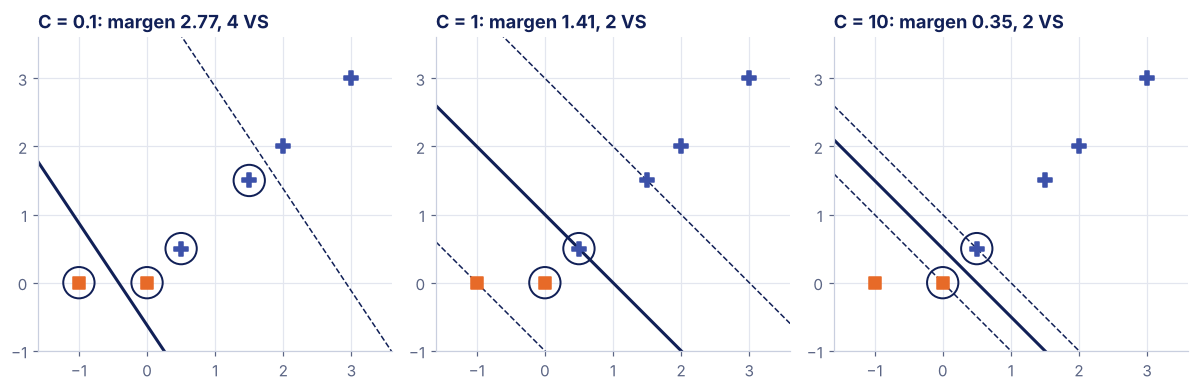

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.7))
for ax, (C, m) in zip(axs, modelos_C.items()):
    dibuja_svm(ax, X6, y6, m.coef_[0], m.intercept_[0], vs=m.support_vectors_)
    ax.set_title(f"C = {C}: margen {1 / np.linalg.norm(m.coef_[0]):.2f}, {len(m.support_)} VS")
plt.tight_layout()
plt.show()

### Holguras con números

Con $w$ y $b$ fijos, la menor holgura que cumple las dos restricciones, $y_j f(x_j) \ge 1 − \xi_j$ y $\xi_j \ge 0$, es $\xi_j = \max(0,\ 1 − y_j f(x_j))$: la pérdida bisagra (diapositiva 26). La tabla de la diapositiva 25, con $C = 1$:

In [19]:
seis = ["(2, 2)", "(3, 3)", "(1.5, 1.5)", "(0.5, 0.5)", "(0, 0)", "(−1, 0)"]
m1 = modelos_C[1]
f1 = m1.decision_function(X6)
alfa1 = np.zeros(len(X6))
alfa1[m1.support_] = np.abs(m1.dual_coef_[0])
xi1 = np.maximum(0, 1 - y6 * f1)
mitad = 0.5 * m1.coef_[0] @ m1.coef_[0]
print("w =", m1.coef_[0].round(3), "  b =", round(m1.intercept_[0], 3))
print(f"Σξ = {xi1.sum():.2f}   ½||w||² = {mitad:.2f}   objetivo ½||w||² + C Σξ = {mitad + 1 * xi1.sum():.2f}")
pd.DataFrame({"y f(x)": y6 * f1, "ξ": xi1, "α": alfa1}, index=seis).round(3) + 0.0

w = [0.5 0.5]   b = -0.5
Σξ = 1.50   ½||w||² = 0.25   objetivo ½||w||² + C Σξ = 1.75


,y f(x),ξ,α
"(2, 2)",1.5,0.0,0.0
"(3, 3)",2.5,0.0,0.0
"(1.5, 1.5)",1.0,0.0,0.0
"(0.5, 0.5)",0.0,1.0,1.0
"(0, 0)",0.5,0.5,1.0
"(−1, 0)",1.0,0.0,0.0


**Lectura.** Solo pesan los dos puntos con $\alpha = C$: (0.5, 0.5), justo sobre la frontera ($f = 0$, $\xi = 1$), y (0, 0), dentro del margen ($\xi = 0.5$). (1.5, 1.5) y (−1, 0) quedan sobre el margen con $\alpha = 0$, sin ser vectores de soporte. El objetivo vale $0.25 + 1 \cdot 1.5 = 1.75$.

¿Por qué con $C$ chico conviene un margen ancho? Evaluamos el objetivo $\frac{1}{2}\lVert w\rVert^2 + C\sum_j \xi_j$ de cada una de las tres soluciones con cada uno de los tres $C$:

In [20]:
def objetivo(w, b, C):
    return 0.5 * w @ w + C * np.maximum(0, 1 - y6 * (X6 @ w + b)).sum()


soluciones = {C: (m.coef_[0], m.intercept_[0]) for C, m in modelos_C.items()}
pd.DataFrame({f"evaluado con C = {Ce}": {f"la solución de C = {Cs} (margen {1 / np.linalg.norm(ws):.2f})": objetivo(ws, bs, Ce)
                                         for Cs, (ws, bs) in soluciones.items()} for Ce in soluciones}).round(3)

,evaluado con C = 0.1,evaluado con C = 1,evaluado con C = 10
la solución de C = 0.1 (margen 2.77),0.335,2.765,27.065
la solución de C = 1 (margen 1.41),0.400,1.750,15.250
la solución de C = 10 (margen 0.35),4.000,4.000,4.000


**Lectura.** En cada columna, el mínimo está en la diagonal: cada solución es la mejor para su $C$. Con $C = 0.1$, la solución de margen 2.77 cuesta 0.335 y la de margen 0.35, 4: pagar holgura sale más barato que estrechar el margen. Con $C = 10$ es al revés: la holgura de las otras dos cuesta 27.065 y 15.250, y conviene el margen estrecho sin holgura (4).

Un detalle de la solución con $C = 0.1$: sus cuatro vectores de soporte tienen $\alpha = C$, y ninguno queda justo sobre el margen. La fórmula $b = y_s − w\cdot x_s$ necesita uno con $0 < \alpha < C$, así que aquí $b$ no queda determinado:

In [21]:
w01 = soluciones[0.1][0]
candidatos = np.linspace(-0.25, 0.5, 301)
valores = np.array([objetivo(w01, bb, 0.1) for bb in candidatos])
plano = candidatos[np.isclose(valores, valores.min(), atol=1e-9)]
print(f"con w fijo, el objetivo es mínimo para todo b entre {plano.min():.3f} y {plano.max():.3f}; libsvm toma b = {soluciones[0.1][1]:.3f}")

con w fijo, el objetivo es mínimo para todo b entre 0.000 y 0.250; libsvm toma b = 0.125


**Lectura.** Cualquier $b$ entre 0 y 0.25 da el mismo objetivo, y libsvm toma el punto medio, 0.125. Con ese $b$, (0, 0) cae del lado equivocado; con $b = 0$ quedaría justo sobre la frontera.

### La bisagra contra la logarítmica

La diapositiva 27 compara las dos pérdidas en función de $y f(x)$. La logarítmica es la $J(\theta)$ de la sesión 11 escrita con etiquetas ±1. Con $p = 1/(1 + e^{-f(x)})$ hay dos casos: si $y = +1$, $-\ln p = \ln(1 + e^{-f})$; si $y = −1$, $-\ln(1 - p) = -\ln\frac{e^{-f}}{1 + e^{-f}} = \ln(1 + e^{f})$. En los dos, $\ln(1 + e^{-y f(x)})$. Lo comprobamos con valores al azar, con $y' = (y + 1)/2$ en la entropía cruzada:

entropía cruzada:   [0.5524 1.3426 0.3867 0.3296 2.0839]
ln(1 + e^(-y f)):   [0.5524 1.3426 0.3867 0.3296 2.0839]


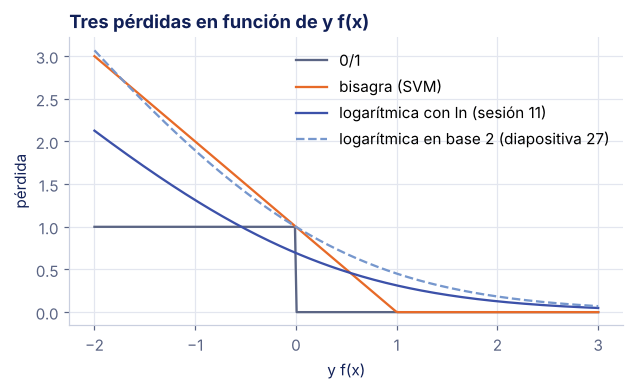

y f(x),-1.0,0.0,0.5,1.0,2.0
bisagra,2.00,1.00,0.50,0.00,0.00
logarítmica (ln),1.31,0.69,0.47,0.31,0.13


In [22]:
rng = np.random.default_rng(SEMILLA)
f = rng.normal(size=5)
y_pm = rng.choice([-1, 1], size=5)
y01 = (y_pm + 1) / 2
p = 1 / (1 + np.exp(-f))
print("entropía cruzada:  ", (-(y01 * np.log(p) + (1 - y01) * np.log(1 - p))).round(4))
print("ln(1 + e^(-y f)):  ", np.log1p(np.exp(-y_pm * f)).round(4))

z = np.linspace(-2, 3, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(z, (z < 0).astype(float), color=GRIS, label="0/1")
ax.plot(z, np.maximum(0, 1 - z), color=NARANJA, label="bisagra (SVM)")
ax.plot(z, np.log1p(np.exp(-z)), color=AZUL_MEDIO, label="logarítmica con ln (sesión 11)")
ax.plot(z, np.log2(1 + np.exp(-z)), color=AZUL, linestyle="--", label="logarítmica en base 2 (diapositiva 27)")
ax.set_xlabel("y f(x)")
ax.set_ylabel("pérdida")
ax.set_title("Tres pérdidas en función de y f(x)")
ax.legend()
plt.show()

zs = np.array([-1, 0, 0.5, 1, 2])
pd.DataFrame({"bisagra": np.maximum(0, 1 - zs), "logarítmica (ln)": np.log1p(np.exp(-zs))},
             index=pd.Index(zs, name="y f(x)")).T.round(2)

**Lectura.** Las dos filas coinciden. La bisagra vale 0 desde $y f(x) = 1$: los ejemplos bien clasificados y fuera del margen no cuentan, y por eso el SVM queda escrito con unos cuantos vectores de soporte. La logarítmica nunca llega a 0: todos los ejemplos cuentan, pero a cambio da probabilidades. La curva de la diapositiva 27 está en base 2 y vale 1 en $y f(x) = 0$; con ln, como en la sesión 11, vale 0.69. En la tabla, con $y f(x) = 0.5$ la bisagra vale 0.50 y la logarítmica 0.47; con $y f(x) = 2$, 0 y 0.13.

### Características de características y el truco del kernel

El ejemplo de la diapositiva 18: en la recta real, −2 y 2 son positivos y −1 y 1, negativos. Ningún umbral los separa, pero con $\phi(x) = (x, x^2)$ sí:

In [23]:
x1d = np.array([-2, 2, -1, 1], dtype=float)
y1d = np.array([1, 1, -1, -1])
Phi = np.column_stack([x1d, x1d ** 2])                   # φ(x) = (x, x²)
en_phi = SVC(kernel="linear", C=1e8).fit(Phi, y1d)
w_phi, b_phi = en_phi.coef_[0], en_phi.intercept_[0]
print("w =", w_phi.round(3), "  b =", round(b_phi, 3), "  margen", round(1 / np.linalg.norm(w_phi), 3))
print("en la recta original, los umbrales quedan en x = ±", round(np.sqrt(-b_phi / w_phi[1]), 3))

w = [0.    0.667]   b = -1.667   margen 1.5
en la recta original, los umbrales quedan en x = ± 1.581


**Lectura.** Por simetría, $w_1 = 0$. Los cuatro puntos son vectores de soporte: $4w_2 + b = 1$ (por ±2) y $w_2 + b = −1$ (por ±1) dan $w_2 = ⅔$ y $b = −5/3$. La frontera es $\frac{2}{3}x^2 − \frac{5}{3} = 0$, o sea $x^2 = 2.5$, con margen $1/\lVert w\rVert = 1.5$. En la recta original son dos umbrales, en ±1.58.

El dual solo necesita productos punto, así que basta con $K(x, z) = \phi(x)\cdot\phi(z) = xz + x^2z^2$ (diapositiva 19). `SVC` acepta el kernel como una función:

In [24]:
def K_juguete(A, B):
    return A @ B.T + (A ** 2) @ (B ** 2).T                # x z + x² z²


con_kernel = SVC(kernel=K_juguete, C=1e8, tol=1e-12).fit(x1d.reshape(-1, 1), y1d)
nuevos = np.array([-2.5, -1.5, 0.0, 1.2, 1.7])
print("K(2, -1) =", K_juguete(np.array([[2.0]]), np.array([[-1.0]]))[0, 0], "   φ(2)·φ(-1) =", np.array([2, 4]) @ np.array([-1, 1]))
print("f con φ explícita:", en_phi.decision_function(np.column_stack([nuevos, nuevos ** 2])).round(3))
print("f con el kernel:  ", con_kernel.decision_function(nuevos.reshape(-1, 1)).round(3))

K(2, -1) = 2.0    φ(2)·φ(-1) = 2
f con φ explícita: [ 2.499 -0.167 -1.667 -0.706  0.26 ]
f con el kernel:   [ 2.5   -0.167 -1.667 -0.707  0.26 ]


**Lectura.** Las dos filas coinciden: el kernel calcula los productos punto del espacio de $\phi$ sin construirlo. Con $D$ atributos, el grado 2 tiene $D + D + D(D − 1)/2 = D(D + 3)/2$ características (77 con los 11 del vino), y el kernel polinomial cuesta lo mismo que el lineal con cualquier grado.

### El kernel de juguete, con números

La matriz $K$ de los cuatro puntos y la frontera escrita solo con los $\alpha$ y $K$ (diapositiva 20). Con $\alpha = 1/9$ en los cuatro, $\sum_j \alpha_j y_j = 0$ y

$$f(x) = \frac{1}{9}\bigl[K(−2, x) + K(2, x) − K(−1, x) − K(1, x)\bigr] + b$$

In [25]:
K4 = K_juguete(x1d.reshape(-1, 1), x1d.reshape(-1, 1))
display(pd.DataFrame(K4.astype(int), index=x1d.astype(int), columns=x1d.astype(int)).rename_axis("K(x, z)"))
alfa_9 = np.full(4, 1 / 9)
b_9 = y1d[0] - (alfa_9 * y1d) @ K4[:, 0]                # b = y_s − Σ alfa_j y_j K(x_j, x_s), con x_s = −2
alfa_svc = np.zeros(4)
alfa_svc[con_kernel.support_] = np.abs(con_kernel.dual_coef_[0])


def W_dual(al):
    return al.sum() - 0.5 * (al * y1d) @ K4 @ (al * y1d)


print(f"b con alfa = 1/9: {b_9:.4f}  (−5/3 = {-5 / 3:.4f})")
print("f con alfa = 1/9:", ((alfa_9 * y1d) @ K_juguete(x1d.reshape(-1, 1), nuevos.reshape(-1, 1)) + b_9).round(3))
print("f de SVC:        ", con_kernel.decision_function(nuevos.reshape(-1, 1)).round(3))
print(f"alfa de SVC: {alfa_svc.round(4)} ({len(con_kernel.support_)} VS); valor del dual: SVC {W_dual(alfa_svc):.4f}, alfa = 1/9 {W_dual(alfa_9):.4f}")

,-2,2,-1,1
"K(x, z)",,,,
-2,20,12,6,2
2,12,20,2,6
-1,6,2,2,0
1,2,6,0,2


b con alfa = 1/9: -1.6667  (−5/3 = -1.6667)
f con alfa = 1/9: [ 2.5   -0.167 -1.667 -0.707  0.26 ]
f de SVC:         [ 2.5   -0.167 -1.667 -0.707  0.26 ]
alfa de SVC: [0.0556 0.1667 0.     0.2222] (3 VS); valor del dual: SVC 0.2222, alfa = 1/9 0.2222


**Lectura.** Con $\alpha = 1/9$, $b = 1 − \frac{1}{9}(20 + 12 − 6 − 2) = −5/3$, y $f(x) = \frac{2}{3}x^2 − \frac{5}{3}$: la misma frontera de la diapositiva 18, sin calcular $\phi$. `SVC` llega a la misma $f$ con otros $\alpha$, $(1/18,\ 1/6,\ 0,\ 2/9)$, y reporta 3 vectores de soporte. Las dos colecciones dan el mismo valor del dual (2/9 = 0.2222) y el mismo $w$: el dual tiene un solo valor óptimo, pero puede alcanzarlo con varios $\alpha$. Por eso los $\alpha$ de la diapositiva y los de `SVC` no coinciden.

### Qué calcula cada kernel

El polinomial de grado 2 con $r = 1$, en 2D, es un producto punto en un espacio de 6 características: $(x\cdot z + 1)^2 = \phi(x)\cdot\phi(z)$, con $\phi(x) = (x_1^2,\ x_2^2,\ \sqrt{2}x_1x_2,\ \sqrt{2}x_1,\ \sqrt{2}x_2,\ 1)$. Con $x = (1, 2)$ y $z = (3, 1)$, término a término (diapositiva 22):

In [26]:
def phi2(v):
    return np.array([v[0] ** 2, v[1] ** 2, np.sqrt(2) * v[0] * v[1], np.sqrt(2) * v[0], np.sqrt(2) * v[1], 1])


xa, za = np.array([1.0, 2.0]), np.array([3.0, 1.0])
terminos = phi2(xa) * phi2(za)
print("(x·z + 1)² =", (xa @ za + 1) ** 2, "   φ(x)·φ(z) =", round(phi2(xa) @ phi2(za), 6))
print("término a término:", terminos.round(3))
print("con coef0 = 0, (x·z)² =", (xa @ za) ** 2, "= los tres primeros términos:", round(terminos[:3].sum(), 3))

(x·z + 1)² = 36.0    φ(x)·φ(z) = 36.0
término a término: [ 9.  4. 12.  6.  4.  1.]
con coef0 = 0, (x·z)² = 25.0 = los tres primeros términos: 25.0


**Lectura.** 36 = 9 + 4 + 12 + 6 + 4 + 1. Con `coef0 = 0`, $(x\cdot z)^2 = 25 = 9 + 4 + 12$: solo quedan los términos de grado 2, sin los de grado 1 ni la constante. Por eso el grado 2 con `coef0 = 0` no separa las lunas (abajo) y pierde en el vino (sección 4).

El RBF, $K(x, z) = e^{−\gamma\lVert x − z\rVert^2}$ con $\gamma = 1/(2\sigma^2)$, decae con la distancia. Cuánto pesa en $f$ un vector de soporte a distancia $d$, según $\gamma$ (diapositivas 22 y 28):

In [27]:
gammas, ds = [0.1, 1, 10], [0.5, 1, 2, 3]
pd.DataFrame({f"d = {d}": [np.exp(-g * d ** 2) for g in gammas] for d in ds},
             index=[f"γ = {g} (σ = {np.sqrt(1 / (2 * g)):.2f})" for g in gammas]).map(lambda v: f"{v:.2g}")

,d = 0.5,d = 1,d = 2,d = 3
γ = 0.1 (σ = 2.24),0.98,0.9,0.67,0.41
γ = 1 (σ = 0.71),0.78,0.37,0.018,0.00012
γ = 10 (σ = 0.22),0.082,4.5e-05,4.2e-18,8.2e-40


**Lectura.** Con $\gamma = 1$, un vector de soporte a distancia 1 vota con $0.37\,\alpha_j$, y a distancia 2, con $0.018\,\alpha_j$: casi nada. Con $\gamma = 10$, ya a distancia 1 su voto es de 0.000045: cada punto solo se influye a sí mismo y la frontera rodea cada punto (diapositiva 29). Con $\gamma = 0.1$, hasta un vector a distancia 3 vota con $0.41\,\alpha_j$: todos influyen lejos y la frontera se parece a la lineal.

### Kernels y gamma en make_moons

Los datos de la diapositiva 29: 200 puntos de `make_moons` con ruido 0.25, estandarizados. Comparamos kernels con validación cruzada estratificada de 5 pliegues; la fórmula de cada uno está en la diapositiva 21. Ojo con `coef0`, el $r$ del polinomial, que por omisión vale 0.

In [28]:
from sklearn.base import clone
from sklearn.datasets import make_moons
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_lunas, y_lunas = make_moons(n_samples=200, noise=0.25, random_state=3)
cv_lunas = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
kernels = {
    "lineal": SVC(kernel="linear"),
    "polinomial, grado 2, coef0 = 0": SVC(kernel="poly", degree=2),
    "polinomial, grado 2, coef0 = 1": SVC(kernel="poly", degree=2, coef0=1),
    "polinomial, grado 3, coef0 = 0": SVC(kernel="poly", degree=3),
    "polinomial, grado 3, coef0 = 1": SVC(kernel="poly", degree=3, coef0=1),
    "RBF, gamma = 0.1": SVC(gamma=0.1),
    "RBF, gamma = 1": SVC(gamma=1),
    "RBF, gamma = 10": SVC(gamma=10),
    "RBF, gamma = 100": SVC(gamma=100),
}
lunas = {}
for nombre, svc in kernels.items():
    modelo = make_pipeline(StandardScaler(), clone(svc))
    lunas[nombre] = {"exactitud, VC": cross_val_score(modelo, X_lunas, y_lunas, cv=cv_lunas).mean(),
                     "vectores de soporte": int(modelo.fit(X_lunas, y_lunas)[-1].n_support_.sum())}
pd.DataFrame(lunas).T.astype({"vectores de soporte": int}).round(3)

,"exactitud, VC",vectores de soporte
lineal,0.860,64
"polinomial, grado 2, coef0 = 0",0.500,196
"polinomial, grado 2, coef0 = 1",0.840,64
"polinomial, grado 3, coef0 = 0",0.840,75
"polinomial, grado 3, coef0 = 1",0.955,52
"RBF, gamma = 0.1",0.865,78
"RBF, gamma = 1",0.955,50
"RBF, gamma = 10",0.950,132
"RBF, gamma = 100",0.820,195


**Lectura.** El lineal se queda en 86 %. El polinomial de grado 2 con `coef0 = 0` es solo $(\gamma\, x\cdot z)^2$: le faltan los términos de grado 1 y no pasa del azar (50 %, con 196 de los 200 puntos como VS); con `coef0 = 1` llega a 84 %. El RBF con $\gamma = 1$ empata con el polinomial de grado 3 y `coef0 = 1` (95.5 %). Con $\gamma = 0.1$ se parece al lineal; con $\gamma = 100$, 195 puntos son VS y la exactitud baja a 82 %.

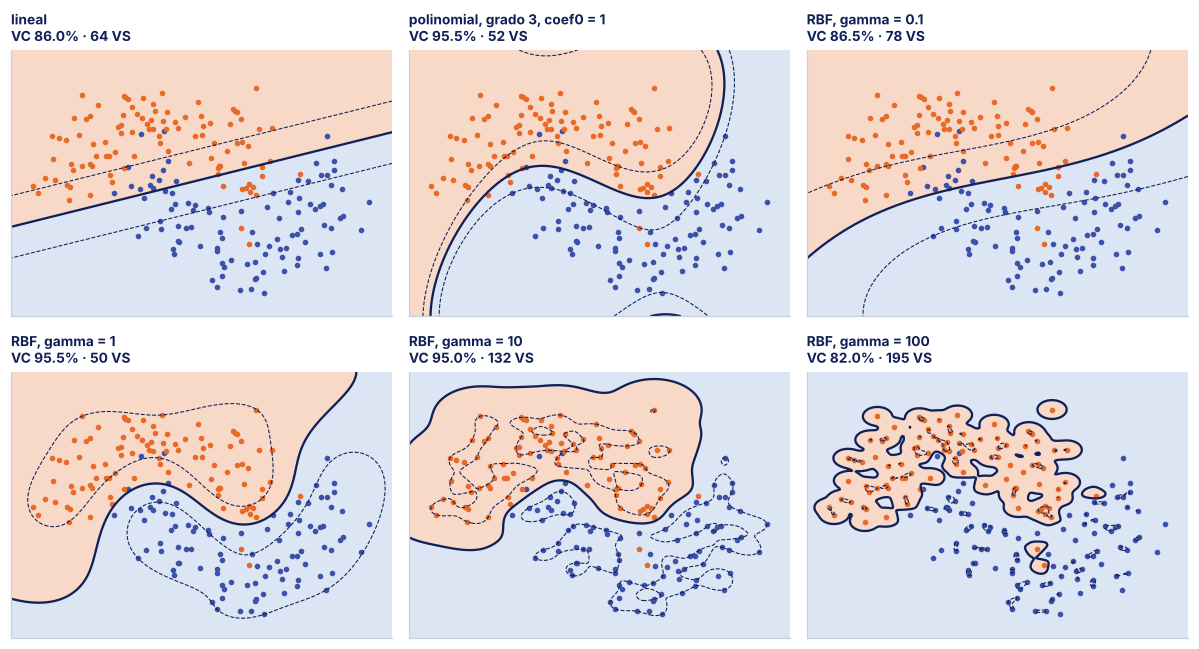

In [29]:
Z_lunas = StandardScaler().fit_transform(X_lunas)
xx, yy = np.meshgrid(np.linspace(-2.4, 2.4, 300), np.linspace(-2.6, 2.6, 300))
paneles = ["lineal", "polinomial, grado 3, coef0 = 1", "RBF, gamma = 0.1", "RBF, gamma = 1", "RBF, gamma = 10", "RBF, gamma = 100"]
fig, axs = plt.subplots(2, 3, figsize=(11, 6))
for ax, nombre in zip(axs.ravel(), paneles):
    m = clone(kernels[nombre]).fit(Z_lunas, y_lunas)
    F = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, F > 0, levels=[-0.5, 0.5, 1.5], colors=["#F8D9C8", "#DCE5F3"])
    ax.contour(xx, yy, F, levels=[0], colors=[AZUL_OSCURO], linewidths=1.5)
    ax.contour(xx, yy, F, levels=[-1, 1], colors=[AZUL_OSCURO], linewidths=0.7, linestyles="--")
    ax.scatter(*Z_lunas[y_lunas == 1].T, s=7, color=AZUL_MEDIO)
    ax.scatter(*Z_lunas[y_lunas == 0].T, s=7, color=NARANJA)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_title(f"{nombre}\nVC {lunas[nombre]['exactitud, VC']:.1%} · {lunas[nombre]['vectores de soporte']} VS", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura.** Las líneas punteadas son $f(x) = \pm 1$. Con $\gamma$ chico, cada vector de soporte influye lejos y la frontera es suave; con $\gamma$ grande, cada uno influye solo cerca de sí y la frontera rodea cada grupo de puntos. Es el voto ponderado por parecido de la diapositiva 28, pariente del kNN con pesos por distancia de la sesión 15.

---

## 3. El caso de estudio: los 14 días

### Nuestro ejemplo

Primero, la instancia de las sesiones 13 a 15, {sunny, cool, high, strong}, con los atributos nominales en *one-hot*:

In [30]:
from sklearn.preprocessing import OneHotEncoder

X_nominal = nominal.drop(columns=["Day", "Play"])
uno = OneHotEncoder().fit(X_nominal)
consulta = pd.DataFrame([{"Outlook": "sunny", "Temperature": "cool", "Humidity": "high", "Wind": "strong"}])
for nombre, parametros in {"lineal, C = 1": dict(kernel="linear", C=1), "RBF por omisión": {}}.items():
    m = SVC(**parametros).fit(uno.transform(X_nominal), nominal.Play)
    f = m.decision_function(uno.transform(consulta))[0]
    print(f"{nombre:16s} f = {f:6.3f} → {'Sí' if f > 0 else 'No'}   ({m.n_support_.sum()} vectores de soporte de 14)")

lineal, C = 1    f = -1.524 → No   (10 vectores de soporte de 14)
RBF por omisión  f =  0.044 → Sí   (14 vectores de soporte de 14)


**Lectura.** El lineal dice No, como el árbol de la sesión 13 y Naive Bayes de la sesión 14. El RBF por omisión dice Sí por muy poco ($f = 0.04$), con los 14 días como vectores de soporte: con tan pocos datos, no resume nada.

### Los días con números

Los 14 días de entrenamiento y los 14 de prueba de la sesión 15, con su codificación (diapositiva 35): *one-hot* para `Outlook`, z-scores para la temperatura y la humedad y 0/1 para el viento. Todo va en el `Pipeline`, así que cada partición aprende sus $\mu$ y $\sigma$.

In [31]:
from sklearn.compose import make_column_transformer

COLUMNAS = ["Outlook", "Temperature", "Humidity", "Wind"]
CIELO = ["sunny", "overcast", "rain"]


def prepara_weather():
    return make_column_transformer(
        (OneHotEncoder(categories=[CIELO]), ["Outlook"]),
        (StandardScaler(), ["Temperature", "Humidity"]),
        (OneHotEncoder(categories=[["weak", "strong"]], drop="first"), ["Wind"]))


def svm_weather(**parametros):
    return make_pipeline(prepara_weather(), SVC(**parametros))


lineal = svm_weather(kernel="linear", C=1).fit(entrena[COLUMNAS], entrena.Play)
svc_l = lineal[-1]
print("b =", round(svc_l.intercept_[0], 3), "   ||w|| =", round(np.linalg.norm(svc_l.coef_[0]), 2),
      "   margen 1/||w|| =", round(1 / np.linalg.norm(svc_l.coef_[0]), 3))
pd.Series(svc_l.coef_[0], index=["sunny", "overcast", "rain", "temperatura (z)", "humedad (z)", "viento fuerte"]).round(3).to_frame("w")

b = 0.834    ||w|| = 1.47    margen 1/||w|| = 0.681


,w
sunny,-0.873
overcast,0.873
rain,0.000
temperatura (z),-0.216
humedad (z),-0.752
viento fuerte,-0.127


**Lectura.** Se lee como el árbol de la sesión 13: overcast empuja a Sí (+0.87); sunny (−0.87) y la humedad alta (−0.75), a No. La temperatura y el viento pesan poco.

### El día 15, a mano

La sustitución de la diapositiva 35. El `StandardScaler` usa la media y la desviación estándar (dividiendo entre $n$) de los 14 días de entrenamiento:

In [32]:
mu = entrena[["Temperature", "Humidity"]].mean()
sd = entrena[["Temperature", "Humidity"]].std(ddof=0)
dia15 = prueba.iloc[0]
print(f"día {dia15.Day}: {dia15.Outlook}, {dia15.Temperature}, {dia15.Humidity}, {dia15.Wind}")
print(f"temperatura: z = ({dia15.Temperature} − {mu.Temperature:.2f}) / {sd.Temperature:.2f} = {(dia15.Temperature - mu.Temperature) / sd.Temperature:.2f}")
print(f"humedad:     z = ({dia15.Humidity} − {mu.Humidity:.2f}) / {sd.Humidity:.2f} = {(dia15.Humidity - mu.Humidity) / sd.Humidity:.2f}")
x15 = lineal[0].transform(prueba[COLUMNAS].iloc[[0]])[0]
terminos15 = pd.DataFrame({"x": x15, "w": svc_l.coef_[0], "w·x": svc_l.coef_[0] * x15},
                          index=["sunny", "overcast", "rain", "temperatura (z)", "humedad (z)", "viento fuerte"])
print(f"Σ w·x = {terminos15['w·x'].sum():.3f}   b = {svc_l.intercept_[0]:.3f}   f = {terminos15['w·x'].sum() + svc_l.intercept_[0]:.3f}")
terminos15.round(3) + 0.0

día 15: sunny, 81, 88, strong
temperatura: z = (81 − 73.57) / 6.33 = 1.17
humedad:     z = (88 − 81.64) / 9.91 = 0.64
Σ w·x = -1.736   b = 0.834   f = -0.903


,x,w,w·x
sunny,1.000,-0.873,-0.873
overcast,0.000,0.873,0.000
rain,0.000,0.000,0.000
temperatura (z),1.173,-0.216,-0.254
humedad (z),0.641,-0.752,-0.482
viento fuerte,1.000,-0.127,-0.127


**Lectura.** $f = −0.87 − 0.22(1.17) − 0.75(0.64) − 0.13 + 0.83 = −0.90$: No, su clase real. Como $|f| < 1$, el día 15 cae dentro del margen: el SVM acierta, pero sin la seguridad de un punto fuera de la banda.

### Los tres tipos de días

Con `dual_coef_` recuperamos el $\alpha$ de cada día (diapositiva 24).

In [33]:
alfa_dias = np.zeros(len(entrena))
alfa_dias[svc_l.support_] = np.abs(svc_l.dual_coef_[0])
y_dias = np.where(entrena.Play, 1, -1)
tipo = np.select([alfa_dias < 1e-8, alfa_dias > 1 - 1e-6], ["fuera del margen", "α = C"], "sobre el margen")
print("Σ alfa_j y_j =", round(float(alfa_dias @ y_dias), 6))
pd.DataFrame({"Day": entrena.Day, "Play": entrena.Play, "y f(x)": (y_dias * lineal.decision_function(entrena[COLUMNAS])).round(2),
              "α": alfa_dias.round(3), "tipo": tipo}).set_index("Day")

Σ alfa_j y_j = 0.0


,Play,y f(x),α,tipo
Day,,,,
1,False,0.69,1.000,α = C
2,False,1.02,0.000,fuera del margen
3,True,1.05,0.000,fuera del margen
4,True,-0.13,1.000,α = C
5,True,1.15,0.000,fuera del margen
6,False,-1.88,1.000,α = C
7,True,3.17,0.000,fuera del margen
8,False,1.00,0.997,sobre el margen
9,True,1.00,0.124,sobre el margen


**Lectura.** Cinco días quedan fuera del margen y no cuentan (2, 3, 5, 7 y 13). Tres quedan sobre él (8, 9 y 12), con $y f(x) = 1$. Los otros seis tienen $\alpha = C$, y de esos, 4, 6 y 14 caen del lado equivocado ($y f(x) < 0$). Son 9 vectores de soporte de 14, y $\sum_j \alpha_j y_j = 0$, como pide el dual.

### Los 14 días de prueba

In [34]:
resumen = {}
for nombre, parametros in {"lineal, C = 1": dict(kernel="linear", C=1), "RBF, C = 1 (por omisión)": dict(C=1), "RBF, C = 10": dict(C=10)}.items():
    m = svm_weather(**parametros).fit(entrena[COLUMNAS], entrena.Play)
    pred = m.predict(prueba[COLUMNAS])
    resumen[nombre] = {"aciertos": int((pred == prueba.Play).sum()), "vectores de soporte": int(m[-1].n_support_.sum()),
                       "días fallados": prueba.Day[pred != prueba.Play].tolist()}
print("Día 15 (sunny, 81, 88, strong), SVM lineal: f =", round(lineal.decision_function(prueba[COLUMNAS].iloc[[0]])[0], 3))
pd.DataFrame(resumen).T

Día 15 (sunny, 81, 88, strong), SVM lineal: f = -0.903


,aciertos,vectores de soporte,días fallados
"lineal, C = 1",11,9,"[18, 20, 27]"
"RBF, C = 1 (por omisión)",11,13,"[18, 20, 27]"
"RBF, C = 10",12,13,"[18, 27]"


**Lectura.** El lineal y el RBF por omisión aciertan 11 de 14; el RBF con $C = 10$, 12. El día 15 sale No ($f = −0.90$), su clase real. Los días 18 y 27 fallan en los tres: sus etiquetas contradicen al árbol de la sesión 13 (un día sunny con humedad de 75 que dice No, y un día rain con viento débil que dice No).

### Elegir C y gamma sin mirar la prueba

Como con $k$ en la sesión 15: elegimos dejando uno fuera en los 14 días de entrenamiento, y la prueba se usa una sola vez (diapositiva 36). La rejilla tiene el kernel lineal y el RBF, $C$ de 0.01 a 1000 y $\gamma$ de 0.01 a 3, más `"scale"`: 80 combinaciones. Para ver qué tan engañosa sería la prueba, también la anotamos, aunque no se use para elegir.

In [35]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_predict

filas = []
for kernel in ["linear", "rbf"]:
    for C in [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 1000]:
        for gamma in ([None] if kernel == "linear" else [0.01, 0.03, 0.1, 0.3, 1, 3, "scale"]):
            parametros = dict(kernel=kernel, C=C) if gamma is None else dict(kernel=kernel, C=C, gamma=gamma)
            loo = cross_val_predict(svm_weather(**parametros), entrena[COLUMNAS], entrena.Play, cv=LeaveOneOut())
            pred = svm_weather(**parametros).fit(entrena[COLUMNAS], entrena.Play).predict(prueba[COLUMNAS])
            filas.append({"kernel": kernel, "C": C, "gamma": gamma, "dejando uno fuera": int((loo == entrena.Play).sum()),
                          "prueba": int((pred == prueba.Play).sum()), "siempre Sí": bool(pred.all())})
rejilla_dias = pd.DataFrame(filas)
base = cross_val_predict(DummyClassifier(strategy="most_frequent"), entrena[COLUMNAS], entrena.Play, cv=LeaveOneOut())
print("Línea base (siempre Sí), dejando uno fuera:", int((base == entrena.Play).sum()), "de 14")
print("Combinaciones que responden Sí a toda la prueba:", int(rejilla_dias["siempre Sí"].sum()), "de", len(rejilla_dias))
elegidos = rejilla_dias[rejilla_dias["dejando uno fuera"] == rejilla_dias["dejando uno fuera"].max()]
elegidos

Línea base (siempre Sí), dejando uno fuera: 9 de 14
Combinaciones que responden Sí a toda la prueba: 37 de 80


,kernel,C,gamma,dejando uno fuera,prueba,siempre Sí
47,rbf,3.0,0.1,10,11,False
53,rbf,10.0,0.03,10,11,False


**Lectura.** Dejando uno fuera empatan dos RBF con 10 de 14, y los dos dan 11/14 en prueba. Y 37 de las 80 combinaciones responden Sí a toda la prueba: con $C$ chico, o con $\gamma$ chico y $C$ moderado, el SVM queda tan regularizado que solo aprende la clase mayoritaria (la línea base, que dejando uno fuera acierta 9 de 14).

¿Y si eligiéramos con la prueba?

In [36]:
rejilla_dias[rejilla_dias.prueba == rejilla_dias.prueba.max()]

,kernel,C,gamma,dejando uno fuera,prueba,siempre Sí
66,rbf,100.0,0.01,7,13,False


**Lectura.** Ganaría el RBF con $C = 100$ y $\gamma = 0.01$, con 13/14. Pero esa combinación acierta solo 7 de 14 dejando uno fuera: ese 13/14 es suerte con estos días de prueba, y reportarlo sería optimista (notebook 13).

### La unidad en los mismos 14 días

La tabla de la sesión 15 (su diapositiva 27) con dos renglones nuevos, como en la diapositiva 36: la regresión logística de la sesión 11, sin regularizar y con la misma codificación, y el SVM. El árbol y Naive Bayes son los de las sesiones 13 y 14; el kNN, el de la sesión 15, con $k$ elegido dejando uno fuera.

In [37]:
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

arbol = np.where(prueba.Outlook == "overcast", True,
                 np.where(prueba.Outlook == "sunny", prueba.Humidity <= 75, prueba.Wind == "weak"))


def naive_bayes(fila):
    puntaje = {}
    for clase in [True, False]:
        sub = entrena[entrena.Play == clase]
        p = len(sub) / len(entrena) * (sub.Outlook == fila.Outlook).mean() * (sub.Wind == fila.Wind).mean()
        for a in ["Temperature", "Humidity"]:
            p *= norm.pdf(fila[a], sub[a].mean(), sub[a].std(ddof=1))
        puntaje[clase] = p
    return max(puntaje, key=puntaje.get)


def aciertos(modelo):
    return int((modelo.fit(entrena[COLUMNAS], entrena.Play).predict(prueba[COLUMNAS]) == prueba.Play).sum())


loo_k = {k: int((cross_val_predict(make_pipeline(prepara_weather(), KNeighborsClassifier(n_neighbors=k)), entrena[COLUMNAS],
                                   entrena.Play, cv=LeaveOneOut()) == entrena.Play).sum()) for k in [1, 3, 5, 7]}
k_elegido = min(k for k in loo_k if loo_k[k] == max(loo_k.values()))
svm_elegido = elegidos.iloc[0]
unidad_dias = pd.Series({
    "árbol J48 (sesión 13)": int((arbol == prueba.Play).sum()),
    "Naive Bayes (sesión 14)": int((prueba.apply(naive_bayes, axis=1) == prueba.Play).sum()),
    "regresión logística (sesión 11)": aciertos(make_pipeline(prepara_weather(), LogisticRegression(C=np.inf, max_iter=5000))),
    f"kNN, k = {k_elegido} (sesión 15)": aciertos(make_pipeline(prepara_weather(), KNeighborsClassifier(n_neighbors=k_elegido))),
    f"SVM RBF, C = {svm_elegido.C:g}, gamma = {svm_elegido.gamma:g} (dejando uno fuera)": int(svm_elegido.prueba),
    "SVM elegido con la prueba": int(rejilla_dias.prueba.max()),
}, name="aciertos")
unidad_dias.to_frame().assign(exactitud=(unidad_dias / 14).round(2))

,aciertos,exactitud
árbol J48 (sesión 13),12,0.86
Naive Bayes (sesión 14),12,0.86
regresión logística (sesión 11),12,0.86
"kNN, k = 5 (sesión 15)",10,0.71
"SVM RBF, C = 3, gamma = 0.1 (dejando uno fuera)",11,0.79
SVM elegido con la prueba,13,0.93


**Lectura.** El árbol, Naive Bayes y la logística aciertan 12; el SVM elegido como se debe, 11, y el kNN, 10. Un día vale 7 puntos: ninguna diferencia es concluyente. La comparación seria es la de la sección 4, con 1599 vinos.

---

## 4. El vino con el protocolo del notebook 13

Volvemos al vino de 3 clases: 20 % para prueba con los duplicados del mismo lado, validación cruzada agrupada dentro del entrenamiento y la prueba una sola vez.

In [38]:
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.preprocessing import MinMaxScaler

X = vinos.drop(columns="calidad")
y = vinos["calidad"]
grupos = pd.util.hash_pandas_object(vinos, index=False)      # filas idénticas, mismo grupo (notebook 12)

i_entrena, i_prueba = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y, grupos))
X_e, X_p = X.iloc[i_entrena], X.iloc[i_prueba]
y_e, y_p = y.iloc[i_entrena], y.iloc[i_prueba]
g_e = grupos.iloc[i_entrena]
pliegues = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento: {len(i_entrena)} vinos; prueba: {len(i_prueba)}")

Entrenamiento: 1279 vinos; prueba: 320


### La escala

El kernel RBF mide distancias, como el kNN. Además, `gamma="scale"` vale $1/(D\cdot\mathrm{Var}(X))$, con la varianza de **toda** la matriz (diapositiva 30): sin escalar, esa varianza la dominan las dos columnas de SO₂.

In [39]:
def validar(modelo):
    r = cross_validate(modelo, X_e, y_e, groups=g_e, cv=pliegues, scoring="f1_macro", return_train_score=True)
    return {"F1 macro, validación": r["test_score"].mean(), "desv. est.": r["test_score"].std(),
            "F1 macro, entrenamiento": r["train_score"].mean()}


D = X_e.shape[1]
print(f"gamma='scale' sin escalar:     1/(D·Var(X)) = {1 / (D * X_e.to_numpy().var()):.5f}")
print(f"gamma='scale' estandarizado:   1/(D·Var(X)) = {1 / (D * StandardScaler().fit_transform(X_e).var()):.3f} = 1/{D}")
print("Sin escalar, el SVM predice «alta» para", int((SVC().fit(X_e, y_e).predict(X_e) == "alta").sum()), "de", len(X_e), "vinos de entrenamiento")
escalas = pd.DataFrame({
    "RBF por omisión, sin escalar": validar(SVC()),
    "RBF por omisión, en [0, 1]": validar(make_pipeline(MinMaxScaler(), SVC())),
    "RBF por omisión, estandarizado": validar(make_pipeline(StandardScaler(), SVC())),
    "como SMO de Weka: en [0, 1], lineal, C = 1": validar(make_pipeline(MinMaxScaler(), SVC(kernel="linear"))),
}).T
escalas.round(3)

gamma='scale' sin escalar:     1/(D·Var(X)) = 0.00033
gamma='scale' estandarizado:   1/(D·Var(X)) = 0.091 = 1/11
Sin escalar, el SVM predice «alta» para 2 de 1279 vinos de entrenamiento


,"F1 macro, validación",desv. est.,"F1 macro, entrenamiento"
"RBF por omisión, sin escalar",0.376,0.024,0.392
"RBF por omisión, en [0, 1]",0.557,0.030,0.625
"RBF por omisión, estandarizado",0.569,0.024,0.679
"como SMO de Weka: en [0, 1], lineal, C = 1",0.428,0.018,0.441


**Lectura.** Sin escalar, $\gamma = 0.00033$: el kernel solo ve el SO₂, el modelo casi nunca predice «alta» (2 de 1279) y el F1 de validación cae a 0.376. Estandarizado, 0.569; en [0, 1], 0.557. Weka (SMO) normaliza a [0, 1] por omisión, con kernel lineal y $C = 1$, y aquí se queda en 0.428: con los atributos en [0, 1], la misma frontera necesita pesos más grandes, así que el mismo $C$ regulariza más y el modelo se queda corto (0.441 en entrenamiento). En Weka conviene subir $C$. Como en el kNN, el escalador va dentro del `Pipeline`.

### Elegir C y gamma

Una rejilla de 42 combinaciones con RBF y 4 con el kernel lineal, con la validación agrupada (diapositiva 37). Tarda unos segundos.

46 combinaciones en 25 s
Elegido: {'C': 100, 'gamma': 0.03, 'kernel': 'rbf'}
F1 macro de validación: 0.582 ± 0.027   (entrenamiento: 0.807)
Mejor kernel lineal: 0.555


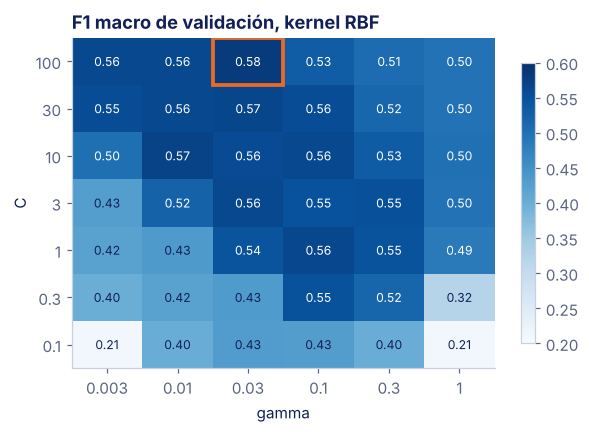

In [40]:
rejilla = [{"svc__kernel": ["rbf"], "svc__C": [0.1, 0.3, 1, 3, 10, 30, 100], "svc__gamma": [0.003, 0.01, 0.03, 0.1, 0.3, 1]},
           {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10]}]
inicio = time.perf_counter()
busqueda = GridSearchCV(make_pipeline(StandardScaler(), SVC()), rejilla, cv=pliegues, scoring="f1_macro",
                        return_train_score=True).fit(X_e, y_e, groups=g_e)
res = pd.DataFrame(busqueda.cv_results_)
elegido = {k.split("__")[1]: v for k, v in busqueda.best_params_.items()}
print(f"{len(res)} combinaciones en {time.perf_counter() - inicio:.0f} s")
print("Elegido:", elegido)
print(f"F1 macro de validación: {busqueda.best_score_:.3f} ± {res.std_test_score[busqueda.best_index_]:.3f}"
      f"   (entrenamiento: {res.mean_train_score[busqueda.best_index_]:.3f})")
print("Mejor kernel lineal:", round(res[res.param_svc__kernel == "linear"].mean_test_score.max(), 3))

mapa = res[res.param_svc__kernel == "rbf"].pivot_table(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")
fig, ax = plt.subplots(figsize=(6.2, 3.9))
im = ax.imshow(mapa.to_numpy(dtype=float), cmap="Blues", origin="lower", aspect="auto", vmin=0.2, vmax=0.6)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.45 else AZUL_OSCURO)
if elegido["kernel"] == "rbf":                  # la combinación elegida, en naranja
    i_mejor, j_mejor = list(mapa.index).index(elegido["C"]), list(mapa.columns).index(elegido["gamma"])
    ax.add_patch(plt.Rectangle((j_mejor - 0.5, i_mejor - 0.5), 1, 1, fill=False, edgecolor=NARANJA, linewidth=2.5))
ax.set_xticks(range(mapa.shape[1]), [f"{g:g}" for g in mapa.columns])
ax.set_yticks(range(mapa.shape[0]), [f"{c:g}" for c in mapa.index])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.grid(False)
ax.set_title("F1 macro de validación, kernel RBF")
plt.colorbar(im, ax=ax, shrink=0.85)
plt.show()

**Lectura.** Gana $C = 100$ con $\gamma = 0.03$: 0.582 ± 0.027 en validación y 0.807 en entrenamiento. El mejor lineal se queda en 0.555. La zona buena es una diagonal: si $\gamma$ crece, conviene bajar $C$. Con $\gamma = 1$, la validación no pasa de 0.50 con ningún $C$.

Ahora la prueba, una sola vez:

In [41]:
svm = busqueda.best_estimator_
pred_svm = svm.predict(X_p)
print(f"SVM elegido, prueba: F1 macro {f1_score(y_p, pred_svm, average='macro'):.3f}, aciertos {accuracy_score(y_p, pred_svm):.4f}")
por_omision = make_pipeline(StandardScaler(), SVC()).fit(X_e, y_e)
print(f"SVC por omisión, la misma prueba: F1 macro {f1_score(y_p, por_omision.predict(X_p), average='macro'):.3f}")
print("Vectores de soporte por clase:", dict(zip(svm[-1].classes_, svm[-1].n_support_.tolist())),
      "→", svm[-1].n_support_.sum(), "de", len(X_e))
print("dual_coef_:", svm[-1].dual_coef_.shape)

SVM elegido, prueba: F1 macro 0.576, aciertos 0.6125


SVC por omisión, la misma prueba: F1 macro 0.593
Vectores de soporte por clase: {'alta': 138, 'baja': 345, 'media': 426} → 909 de 1279
dual_coef_: (2, 909)


**Lectura.** En prueba, 0.576. El SVC por omisión da 0.593 en la misma prueba: la búsqueda no ganó nada. El mejor de 46 candidatos sale optimista en validación (notebook 13), y con 320 vinos, una diferencia de 0.02 es ruido.

909 de los 1279 vinos son vectores de soporte (71 %): con clases que se traslapan, el SVM casi no resume los datos (diapositiva 17). `dual_coef_` tiene 2 filas porque `SVC` entrena uno contra uno, y cada vector de soporte participa en los 2 clasificadores de su clase (sección 5).

### El polinomial y coef0

El detalle de las diapositivas 21 y 22, ahora en el vino: con `coef0 = 0`, el kernel de grado 2 pierde los términos de grado 1.

In [42]:
for coef0 in [0, 1]:
    r = validar(make_pipeline(StandardScaler(), SVC(kernel="poly", degree=2, coef0=coef0)))
    print(f"grado 2, coef0 = {coef0}: F1 macro de validación {r['F1 macro, validación']:.3f}")

grado 2, coef0 = 0: F1 macro de validación 0.438


grado 2, coef0 = 1: F1 macro de validación 0.568


**Lectura.** De 0.438 a 0.568: el mismo tropiezo que en make_moons. Sin el término de grado 1, el kernel solo ve los cuadrados y los productos de pares de atributos.

### Probabilidades

`SVC` no da probabilidades: `decision_function` es una distancia con signo. En scikit-learn 1.9, `probability=True` está deprecado y se quita en la versión 1.11: ajustaba una sigmoide (Platt, 1999) con una validación cruzada interna, y sus probabilidades podían contradecir a `predict`.

In [43]:
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    viejo = make_pipeline(StandardScaler(), SVC(**elegido, probability=True, random_state=0)).fit(X_e, y_e)
    P_viejo = viejo.predict_proba(X_p)
for aviso in {str(a.message) for a in avisos if issubclass(a.category, FutureWarning)}:
    print("Aviso:", aviso)
contradicen = int((viejo[-1].classes_[P_viejo.argmax(axis=1)] != viejo.predict(X_p)).sum())
print(f"probability=True: la clase más probable no es la de predict en {contradicen} de {len(X_p)} vinos")

Aviso: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
probability=True: la clase más probable no es la de predict en 28 de 320 vinos


**Lectura.** En 28 de los 320 vinos, la clase con mayor probabilidad no es la que predice el mismo modelo. La alternativa es `CalibratedClassifierCV` con `ensemble=False`: ajusta la sigmoide con las predicciones de una validación cruzada y se queda con un solo SVM entrenado con todo (diapositiva 30). Le pasamos los mismos pliegues agrupados.

In [44]:
from sklearn.calibration import CalibratedClassifierCV

cortes = list(pliegues.split(X_e, y_e, g_e))
calibrado = CalibratedClassifierCV(make_pipeline(StandardScaler(), SVC(**elegido)), ensemble=False, cv=cortes).fit(X_e, y_e)
P_svm = calibrado.predict_proba(X_p)
print(f"log-loss {log_loss(y_p, P_svm, labels=calibrado.classes_):.3f}   confianza media {P_svm.max(axis=1).mean():.3f}")
print("predicciones distintas a las del SVM sin calibrar:", int((calibrado.predict(X_p) != pred_svm).sum()), "de", len(X_p))

log-loss 0.800   confianza media 0.613
predicciones distintas a las del SVM sin calibrar: 3 de 320


**Lectura.** Las probabilidades calibradas dan un log-loss de 0.800 y una confianza media de 0.613, casi igual a la proporción de aciertos (0.6125): no presumen de más. Solo 3 de las 320 predicciones cambian respecto al SVM sin calibrar.

### La unidad 4 en una tabla

Los cinco modelos con la misma partición y el mismo protocolo (diapositiva 39). Los cuatro primeros son los de la tabla del notebook 15; el SVM es el elegido, con el log-loss de las probabilidades calibradas.

In [45]:
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier


def evaluar(modelo):
    r = cross_validate(modelo, X_e, y_e, groups=g_e, cv=pliegues, scoring="f1_macro")
    modelo.fit(X_e, y_e)
    P = modelo.predict_proba(X_p)
    pred = modelo.classes_[P.argmax(axis=1)]
    return {"F1 macro, validación": r["test_score"].mean(), "F1 macro, prueba": f1_score(y_p, pred, average="macro"),
            "aciertos": accuracy_score(y_p, pred), "log-loss": log_loss(y_p, P, labels=modelo.classes_)}


modelos = {
    "regresión logística (11)": make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)),
    "árbol elegido (13)": DecisionTreeClassifier(random_state=0, max_depth=6, min_samples_leaf=5),
    "Naive Bayes (14)": GaussianNB(),
    "kNN elegido (15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=51, weights="distance", p=1)),
}
tabla_unidad = pd.DataFrame({nombre: evaluar(m) for nombre, m in modelos.items()}).T
tabla_unidad.loc["SVM elegido (16)"] = {"F1 macro, validación": busqueda.best_score_, "F1 macro, prueba": f1_score(y_p, pred_svm, average="macro"),
                                        "aciertos": accuracy_score(y_p, pred_svm), "log-loss": log_loss(y_p, P_svm, labels=calibrado.classes_)}
tabla_unidad.round(3)

,"F1 macro, validación","F1 macro, prueba",aciertos,log-loss
regresión logística (11),0.562,0.573,0.619,0.754
árbol elegido (13),0.584,0.551,0.581,3.133
Naive Bayes (14),0.579,0.596,0.612,0.955
kNN elegido (15),0.566,0.584,0.622,0.770
SVM elegido (16),0.582,0.576,0.612,0.800


**Lectura.** Con el mismo protocolo, los cinco quedan entre 0.551 y 0.596 de F1 macro en prueba y entre 0.562 y 0.584 en validación, y entre pliegues la validación varía de 0.02 a 0.05: ninguna diferencia es concluyente. Lo que separa a los modelos es otra cosa. El SVM y el kNN necesitan escalar; el árbol y Naive Bayes, no. El SVM necesita calibrarse para dar probabilidades, y calibrado (0.800) queda junto a la logística (0.754) y el kNN (0.770), lejos del árbol (3.133). Y es el más caro de entrenar (sección 5).

### Los duplicados y gamma

En el notebook 12, la SVM casi no cambió al poner las gemelas en el mismo pliegue, y la explicación fue que no memoriza casos. Con los valores por omisión es cierto. Pero con $\gamma$ grande, el kernel de un vino con su gemela vale 1 y con los demás casi 0: la gemela decide, como en el kNN con pesos por distancia de la sesión 15 (diapositiva 38). Validación cruzada de 10 pliegues en los 1599 vinos, con la partición usual y con las gemelas juntas:

In [46]:
from sklearn.model_selection import StratifiedKFold

usual = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
juntas = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
svms = {"por omisión (C = 1, gamma = 1/11)": SVC(), f"elegido (C = {elegido['C']}, gamma = {elegido['gamma']})": SVC(**elegido),
        "C = 10, gamma = 0.3": SVC(C=10, gamma=0.3), "C = 100, gamma = 1": SVC(C=100, gamma=1)}
duplicados = {}
for nombre, svc in svms.items():
    m = make_pipeline(StandardScaler(), svc)
    duplicados[nombre] = {"partición usual": cross_val_score(m, X, y, cv=usual, scoring="f1_macro").mean(),
                          "gemelas juntas": cross_val_score(m, X, y, cv=juntas, groups=grupos, scoring="f1_macro").mean()}
duplicados = pd.DataFrame(duplicados).T
duplicados["cambio"] = duplicados["gemelas juntas"] - duplicados["partición usual"]
duplicados.round(3)

,partición usual,gemelas juntas,cambio
"por omisión (C = 1, gamma = 1/11)",0.594,0.600,0.006
"elegido (C = 100, gamma = 0.03)",0.645,0.586,-0.059
"C = 10, gamma = 0.3",0.668,0.570,-0.098
"C = 100, gamma = 1",0.658,0.513,-0.145


**Lectura.** Con los valores por omisión, el notebook 12 tenía razón: 0.594 y 0.600. Pero el cambio crece con $\gamma$: con $C = 100$ y $\gamma = 1$, el F1 macro baja de 0.658 a 0.513. Incluso el elegido pierde 0.059.

¿Qué pasa si elegimos $C$ y $\gamma$ con la partición usual? Repetimos la búsqueda dentro del entrenamiento con 5 pliegues normales y con los agrupados. Solo para ilustrar, miramos las dos en la prueba.

In [47]:
rejilla2 = {"svc__C": [0.1, 0.3, 1, 3, 10, 30, 100], "svc__gamma": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]}
for nombre, cv, grupos_cv in [("usual", StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA), None), ("agrupada", pliegues, g_e)]:
    g = GridSearchCV(make_pipeline(StandardScaler(), SVC()), rejilla2, cv=cv, scoring="f1_macro").fit(X_e, y_e, groups=grupos_cv)
    print(f"validación {nombre:8s} elige {({k.split('__')[1]: v for k, v in g.best_params_.items()})}: "
          f"promete {g.best_score_:.3f} y la prueba da {f1_score(y_p, g.best_estimator_.predict(X_p), average='macro'):.3f}")

validación usual    elige {'C': 10, 'gamma': 0.3}: promete 0.663 y la prueba da 0.547


validación agrupada elige {'C': 100, 'gamma': 0.03}: promete 0.582 y la prueba da 0.576


**Lectura.** Con la partición usual, la validación premia a los modelos que reconocen gemelas: elige $\gamma = 0.3$, promete 0.663 y en la prueba, sin gemelas del entrenamiento, da 0.547. La agrupada promete menos (0.582) y cumple (0.576). Agrupar los duplicados decide qué $\gamma$ se elige.

---

## 5. Varias clases y el costo de entrenar

### Uno contra uno

`SVC` entrena un clasificador por cada par de clases y las deja votar (diapositiva 33). Con las flores de Iris y las dos medidas del pétalo, una flor de 4.9 × 1.6 cm:

In [48]:
from sklearn.datasets import load_iris

iris = load_iris()
X_iris = iris.data[:, 2:4]                     # largo y ancho del pétalo
ovo = SVC(kernel="linear", decision_function_shape="ovo").fit(X_iris, iris.target)
flor = [[4.9, 1.6]]
for (a, c), f in zip([(0, 1), (0, 2), (1, 2)], ovo.decision_function(flor)[0]):
    print(f"{iris.target_names[a]:>10} contra {iris.target_names[c]:<10}  f = {f:6.2f}  → gana {iris.target_names[a] if f > 0 else iris.target_names[c]}")
print("predicción:", iris.target_names[ovo.predict(flor)[0]])
ovr = SVC(kernel="linear").fit(X_iris, iris.target)
print('con decision_function_shape="ovr", una columna por clase:', ovr.decision_function(flor).round(2))

    setosa contra versicolor  f =  -3.23  → gana versicolor
    setosa contra virginica   f =  -1.22  → gana virginica
versicolor contra virginica   f =   0.11  → gana versicolor
predicción: versicolor
con decision_function_shape="ovr", una columna por clase: [[-0.27  2.26  1.17]]


**Lectura.** Un $f$ positivo vota por la primera clase del par. Versicolor gana dos de los tres duelos: contra setosa ($f = −3.23$) y contra virginica, por poco ($f = 0.11$). Con `decision_function_shape="ovr"`, el valor por omisión, `SVC` sigue entrenando uno contra uno: solo acomoda la salida en una columna por clase, con los votos (0, 2 y 1) más un ajuste chico según la confianza.

### Una sola formulación: Crammer y Singer

La diapositiva 34 aprende los $c$ conjuntos de pesos a la vez. Cada clase tiene su puntaje, $s_k(x) = w^{(k)}\cdot x + b^{(k)}$; la clase real de cada ejemplo debe ganarle a cada rival por al menos 1, y si no, paga una holgura. `LinearSVC(multi_class="crammer_singer")` lo resuelve con una holgura por ejemplo: la del rival más fuerte. Con la misma flor:

In [49]:
from sklearn.svm import LinearSVC

cs = LinearSVC(multi_class="crammer_singer", C=1, max_iter=200000, tol=1e-8, random_state=0).fit(X_iris, iris.target)
s = cs.decision_function(flor)[0]
for nombre, v in zip(iris.target_names, s):
    print(f"{nombre:>10}: s = {v:5.2f}")
print("predicción:", iris.target_names[s.argmax()])
print(f"si fuera versicolor de entrenamiento, contra virginica: {s[1]:.2f} ≥ {s[2]:.2f} + 1 − ξ  →  ξ = {max(0, 1 - (s[1] - s[2])):.2f}")
print(f"                                    contra setosa:    {s[1]:.2f} ≥ {s[0]:.2f} + 1 − ξ  →  ξ = {max(0, 1 - (s[1] - s[0])):.2f}")

    setosa: s = -1.65
versicolor: s =  0.90
 virginica: s =  0.75
predicción: versicolor
si fuera versicolor de entrenamiento, contra virginica: 0.90 ≥ 0.75 + 1 − ξ  →  ξ = 0.86
                                    contra setosa:    0.90 ≥ -1.65 + 1 − ξ  →  ξ = 0.00


**Lectura.** Versicolor gana con 0.90, pero virginica la sigue de cerca (0.75). Si esta flor fuera una versicolor de entrenamiento, su restricción contra virginica pediría $0.90 \ge 0.75 + 1 − \xi$: le falta margen y paga $\xi = 0.86$. Contra setosa (−1.65) le sobra margen.

### ¿Importa el esquema?

`LinearSVC`, en cambio, entrena uno contra el resto por omisión (diapositiva 32); con `multi_class="crammer_singer"`, la formulación conjunta que acabamos de ver. Con 3 clases, los dos esquemas entrenan 3 clasificadores; con 10 clases, uno contra el resto entrena 10 y uno contra uno, 45. Para separar el esquema del algoritmo, ponemos el mismo `LinearSVC` en los dos, con las predicciones de validación de los 5 pliegues agrupados del vino:

In [50]:
from sklearn.metrics import recall_score
from sklearn.multiclass import OneVsOneClassifier

esquemas = {"LinearSVC (uno contra el resto)": LinearSVC(),
            "OneVsOneClassifier(LinearSVC())": OneVsOneClassifier(LinearSVC()),
            "SVC(kernel='linear') (uno contra uno)": SVC(kernel="linear")}
filas = {}
for nombre, m in esquemas.items():
    p = cross_val_predict(make_pipeline(StandardScaler(), m), X_e, y_e, groups=g_e, cv=pliegues)
    filas[nombre] = dict(zip(["recall baja", "recall media", "recall alta"], recall_score(y_e, p, labels=["baja", "media", "alta"], average=None)))
    filas[nombre]["F1 macro"] = f1_score(y_e, p, average="macro")
print("Proporción de cada clase:", y_e.value_counts(normalize=True).round(3).to_dict())
pd.DataFrame(filas).T.round(3)

Proporción de cada clase: {'baja': 0.465, 'media': 0.399, 'alta': 0.136}


,recall baja,recall media,recall alta,F1 macro
LinearSVC (uno contra el resto),0.812,0.537,0.138,0.495
OneVsOneClassifier(LinearSVC()),0.763,0.555,0.362,0.575
SVC(kernel='linear') (uno contra uno),0.758,0.547,0.322,0.556


**Lectura.** El esquema pesa más que el algoritmo: con el mismo `LinearSVC`, pasar de uno contra el resto a uno contra uno sube el F1 macro de 0.495 a 0.575. La diferencia está en «alta», 14 % de los vinos. Contra el resto, su clasificador separa 14 % contra 86 %, casi nunca gana la votación y recupera 14 % de los vinos «alta»; uno contra uno, «alta» se compara con cada clase por separado y recupera 36 %.

### Pesos por clase

Otra forma de ayudar a «alta» es pesarla más. Con `class_weight="balanced"`, cada clase pesa $n/(c\cdot n_k)$, inversamente a su frecuencia, y en `SVC` ese peso multiplica a $C$: el tope de los $\alpha$ de la clase $k$ pasa a ser $C$ por su peso (diapositiva 30). En el vino, con el SVM elegido en la sección 4:

In [51]:
from sklearn.utils.class_weight import compute_class_weight

clases = ["baja", "media", "alta"]
pesos = compute_class_weight("balanced", classes=np.array(clases), y=y_e)
print(pd.DataFrame({"n_k": y_e.value_counts()[clases].to_numpy(), "peso n/(c·n_k)": pesos.round(3),
                    f"tope de α (C = {elegido['C']:g})": (elegido["C"] * pesos).round(1)}, index=clases).to_string(), "\n")
filas = {}
for nombre, pesos_ in [("sin pesos", None), ('class_weight="balanced"', "balanced")]:
    p = cross_val_predict(make_pipeline(StandardScaler(), SVC(**elegido, class_weight=pesos_)), X_e, y_e, groups=g_e, cv=pliegues)
    filas[nombre] = dict(zip(["recall baja", "recall media", "recall alta"], recall_score(y_e, p, labels=clases, average=None)))
    filas[nombre]["F1 macro"] = f1_score(y_e, p, average="macro")
pd.DataFrame(filas).T.round(3)

       n_k  peso n/(c·n_k)  tope de α (C = 100)
baja   595           0.717                 71.7
media  510           0.836                 83.6
alta   174           2.450                245.0 



,recall baja,recall media,recall alta,F1 macro
sin pesos,0.731,0.557,0.448,0.581
"class_weight=""balanced""",0.706,0.494,0.592,0.576


**Lectura.** Con 174 vinos «alta» de 1279, su peso es 2.45: el tope de sus $\alpha$ sube de 100 a 245, y el de «baja» baja a 72. El recall de «alta» sube de 0.45 a 0.59, pero «media» cae de 0.56 a 0.49 y el F1 macro queda igual (0.581 y 0.576). Los pesos no agregan información: mueven la frontera para que la clase chica pese lo mismo que las otras. Convienen cuando importa más no perder la clase chica, y se eligen como cualquier hiperparámetro, en la validación.

### El costo de entrenar

`SVC` resuelve un QP cuyo tamaño crece con el número de ejemplos. Según la documentación de scikit-learn, el tiempo de ajuste crece al menos con $n^2$, y más allá de decenas de miles de ejemplos se vuelve impráctico. `LinearSVC` crece casi en línea recta. Lo medimos con datos sintéticos de 20 atributos (mediana de 3 repeticiones):

In [52]:
from sklearn.datasets import make_classification

tiempos = {}
for n in [1000, 2000, 4000, 8000, 16000]:
    X_s, y_s = make_classification(n_samples=n, n_features=20, n_informative=10, flip_y=0.1, random_state=0)
    X_s = StandardScaler().fit_transform(X_s)
    fila = {}
    for nombre, modelo in [("SVC, RBF (s)", SVC()), ("LinearSVC (s)", LinearSVC())]:
        medidas = []
        for _ in range(3):
            inicio = time.perf_counter()
            modelo.fit(X_s, y_s)
            medidas.append(time.perf_counter() - inicio)
        fila[nombre] = np.median(medidas)
    tiempos[n] = fila
tiempos = pd.DataFrame(tiempos).T
tiempos["SVC: veces el anterior"] = tiempos["SVC, RBF (s)"] / tiempos["SVC, RBF (s)"].shift()
tiempos.round(4)

,"SVC, RBF (s)",LinearSVC (s),SVC: veces el anterior
1000,0.0473,0.0055,NaN
2000,0.1630,0.0033,3.4428
4000,0.3264,0.0082,2.0025
8000,1.2986,0.0148,3.9787
16000,4.4368,0.0249,3.4166


**Lectura.** Al duplicar $n$, `SVC` tarda casi 4 veces más, como $n^2$, y `LinearSVC`, unas 2 veces, como $n$ (los números exactos dependen de la máquina). Con 16 000 ejemplos, `SVC` ya tarda segundos; con cientos de miles, de minutos a horas. Para datos grandes, la documentación de scikit-learn recomienda `LinearSVC` o `SGDClassifier`, quizá después de aproximar el kernel con `Nystroem`.

---

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de Claude (Anthropic) para estructurar el contenido a partir de las diapositivas de la sesión, redactar el texto explicativo y preparar los ejemplos. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.

### Referencias

- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20(3), 273-297.
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*, capítulo 7: Sparse Kernel Machines. Springer.
- Platt, J. C. (1998). Sequential minimal optimization: A fast algorithm for training support vector machines. Technical Report MSR-TR-98-14, Microsoft Research.
- Platt, J. C. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. En *Advances in Large Margin Classifiers*, 61-74. MIT Press.
- Chang, C.-C., & Lin, C.-J. (2011). LIBSVM: A library for support vector machines. *ACM Transactions on Intelligent Systems and Technology*, 2(3), 27.
- Shalev-Shwartz, S., Singer, Y., Srebro, N., & Cotter, A. (2011). Pegasos: Primal estimated sub-gradient solver for SVM. *Mathematical Programming*, 127(1), 3-30.
- Weston, J., & Watkins, C. (1999). Support vector machines for multi-class pattern recognition. En *ESANN*, 219-224.
- Crammer, K., & Singer, Y. (2001). On the algorithmic implementation of multiclass kernel-based vector machines. *Journal of Machine Learning Research*, 2, 265-292.
- VanderPlas, J. (2022). *Python Data Science Handbook*, 2a ed. O'Reilly. [Capítulo 43: In Depth: Support Vector Machines](https://jakevdp.github.io/PythonDataScienceHandbook/05.07-support-vector-machines.html).
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547-553.
- [scikit-learn: Support Vector Machines](https://scikit-learn.org/stable/modules/svm.html) · [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) · [LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html) · [CalibratedClassifierCV](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibratedClassifierCV.html)